In [1]:
import sys
import os

sys.path.append(os.path.abspath('..'))

from nn.tensor import Tensor
import numpy as np
from nn.utils import visualize_computation_graph

In [2]:
def visualize_attention_head(): 
    X = Tensor(np.random.randn(2, 8, 16), requires_grad=True)

    W_q = Tensor(np.random.randn(16, 16), requires_grad=True)
    W_k = Tensor(np.random.randn(16, 16), requires_grad=True)
    W_v = Tensor(np.random.randn(16, 16), requires_grad=True)
    W_o = Tensor(np.random.randn(16, 16), requires_grad=True)

    W1 = Tensor(np.random.randn(16, 32), requires_grad=True)
    W2 = Tensor(np.random.randn(32, 16), requires_grad=True)

    Q = X @ W_q
    K = X @ W_k
    V = X @ W_v

    scale = Tensor(16.0 ** 0.5, requires_grad=False)
    scores = (Q @ K.transpose(0, 2, 1)) / scale

    scores_max = scores.max(axis=-1, keepdims=True)
    exp_scores = (scores - scores_max).exp()
    attn_weights = exp_scores / exp_scores.sum(axis=-1, keepdims=True)

    attn_out = (attn_weights @ V) @ W_o

    norm1_in = X + attn_out
    mean1 = norm1_in.mean(axis=-1, keepdims=True)
    var1 = ((norm1_in - mean1) * (norm1_in - mean1)).mean(axis=-1, keepdims=True)
    std1 = (var1 + Tensor(1e-5, requires_grad=False)) ** 0.5  # or (var1 + eps)**0.5
    norm1_out = (norm1_in - mean1) / std1

    hidden = (norm1_out @ W1).leaky_relu()
    mlp_out = hidden @ W2

    out = norm1_out + mlp_out
    loss = out.sum()
    return visualize_computation_graph(loss, "computation_graph.png")

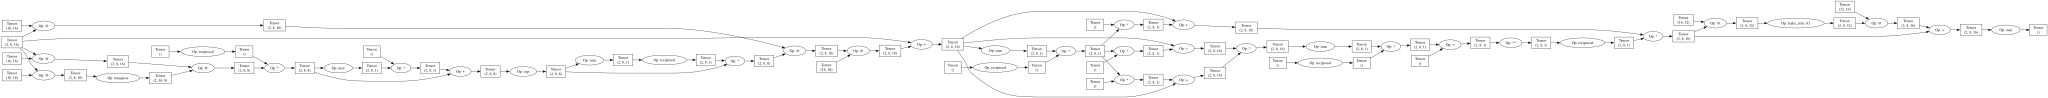

In [3]:
visualize_attention_head()

In [4]:
def visualize_chaotic_lorenz(): 
    seq_len = 10
    X = Tensor(np.random.randn(seq_len, 4, 8), requires_grad=True) # [Seq, Batch, Feature]
    h = Tensor(np.zeros((4, 16)), requires_grad=True)              # Hidden state

    # Split weight matrices for input (8) and hidden state (16)
    W_xz = Tensor(np.random.randn(8, 16), requires_grad=True)
    W_hz = Tensor(np.random.randn(16, 16), requires_grad=True)

    W_xr = Tensor(np.random.randn(8, 16), requires_grad=True)
    W_hr = Tensor(np.random.randn(16, 16), requires_grad=True)

    W_xh = Tensor(np.random.randn(8, 16), requires_grad=True)
    W_hh = Tensor(np.random.randn(16, 16), requires_grad=True)

    def sigmoid(tensor):
        # Sigmoid built from exp: 1 / (1 + exp(-x))
        one = Tensor(1.0, requires_grad=False)
        neg_tensor = tensor * Tensor(-1.0, requires_grad=False)
        return one / (one + neg_tensor.exp())

    # Dynamic Graph Expansion across Time Steps
    for t in range(seq_len):
        x_t = X[t]  # Extract step t (shape: 4, 8)
        
        # Update and Reset Gates using addition instead of concat
        z_t = sigmoid((x_t @ W_xz) + (h @ W_hz))
        r_t = sigmoid((x_t @ W_xr) + (h @ W_hr))
        
        # Candidate Hidden State with gated hidden interaction
        h_candidate = ((x_t @ W_xh) + ((r_t * h) @ W_hh)).tanh()
        
        # Compute next hidden state
        one = Tensor(1.0, requires_grad=False)
        h = (one - z_t) * h + z_t * h_candidate

    loss = h.mean()
    return visualize_computation_graph(loss, "computation_graph.png")

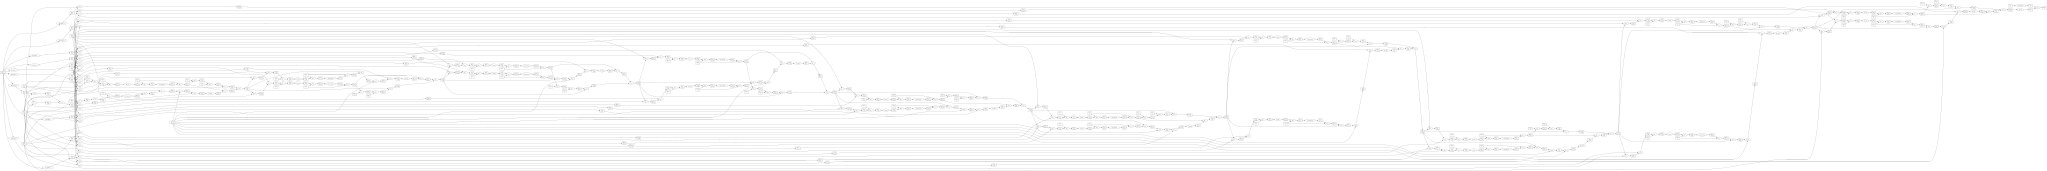

In [5]:
visualize_chaotic_lorenz()